# Ablação do pipeline — 2023

Este notebook usa somente dois arquivos:

- `df_mapeamento_titulados_2023_ETAPA1.csv`: candidatos recuperados pelo embedding e rótulo do Mistral;
- `df_mapeamento_titulados_2023_filtrado.csv`: resultado final do modelo grande (`nivel`).

Execute as células em ordem. Cada uma mostra um estágio do funil: **embedding → Mistral → modelo grande**.

In [1]:
import pandas as pd

ARQUIVO_ETAPA_1 = 'df_mapeamento_titulados_2023_ETAPA1.csv'
ARQUIVO_FINAL = 'df_mapeamento_titulados_2023_filtrado.csv'
CHAVES = ['HASH_ID', 'TEMA_ID']
ROTULOS = ['ALTA', 'MEDIA', 'BAIXA', 'NENHUMA']
POSITIVOS = ['ALTA', 'MEDIA']

In [2]:
def preparar_chaves(df):
    """Remove chaves vazias e padroniza TEMA_ID para permitir o merge."""
    df = df.dropna(subset=CHAVES).copy()
    df['HASH_ID'] = df['HASH_ID'].astype('string').str.strip()
    df['TEMA_ID'] = (df['TEMA_ID'].astype('string').str.strip()
                     .str.replace(r'\.0$', '', regex=True))
    return df.loc[df['HASH_ID'].ne('') & df['TEMA_ID'].ne('')].copy()

# Primeiro carregamos o CSV final: ele define os temas de IA do estudo.
final = pd.read_csv(ARQUIVO_FINAL, usecols=CHAVES + ['nivel'])
final = preparar_chaves(final)
temas_ia = set(final['TEMA_ID'].unique())
final = final.drop_duplicates(CHAVES, keep='last').copy()
final['rotulo_final'] = final['nivel'].where(final['nivel'].isin(ROTULOS), 'SEM_ROTULO')

print(f'Temas de IA: {len(temas_ia)}')
print(f'Pares únicos no CSV final: {len(final):,}')

Temas de IA: 28
Pares únicos no CSV final: 29,936


In [3]:
# ETAPA 1 — embedding. Cada par recuperado é considerado ALTA neste estágio.
etapa_1 = pd.read_csv(ARQUIVO_ETAPA_1)
etapa_1 = preparar_chaves(etapa_1)
etapa_1 = etapa_1.loc[etapa_1['TEMA_ID'].isin(temas_ia)].copy()

duplicatas_etapa_1 = etapa_1.duplicated(CHAVES, keep=False).sum()
etapa_1 = etapa_1.drop_duplicates(CHAVES, keep='last').copy()
etapa_1['rotulo_embedding'] = 'ALTA'

pd.DataFrame({
    'medida': ['Temas de IA', 'Pares recuperados pelo embedding', 'Linhas duplicadas removidas'],
    'quantidade': [etapa_1['TEMA_ID'].nunique(), len(etapa_1), duplicatas_etapa_1],
})

,medida,quantidade
0,Temas de IA,28
1,Pares recuperados pelo embedding,161292
2,Linhas duplicadas removidas,0


In [4]:
# ETAPA 2 — Mistral. Veja a distribuição antes de aplicar o filtro positivo.
etapa_1['rotulo_mistral'] = etapa_1['rotulo_mistral'].where(
    etapa_1['rotulo_mistral'].isin(ROTULOS), 'ERRO'
)
distribuicao_mistral = (etapa_1['rotulo_mistral'].value_counts()
                       .reindex(ROTULOS + ['ERRO'], fill_value=0)
                       .rename_axis('rotulo_mistral').reset_index(name='pares'))
distribuicao_mistral['percentual'] = (100 * distribuicao_mistral['pares'] / len(etapa_1)).round(2)
distribuicao_mistral

,rotulo_mistral,pares,percentual
0,ALTA,13382,8.30
1,MEDIA,14563,9.03
2,BAIXA,27154,16.84
3,NENHUMA,104202,64.60
4,ERRO,1991,1.23


In [5]:
# Mantemos somente ALTA e MEDIA para a próxima etapa.
mistral_positivo = etapa_1.loc[etapa_1['rotulo_mistral'].isin(POSITIVOS),
    CHAVES + ['rotulo_embedding', 'rotulo_mistral']].copy()

print(f'Pares após o filtro do Mistral: {len(mistral_positivo):,}')
print(f'Retenção em relação ao embedding: {len(mistral_positivo) / len(etapa_1):.2%}')
mistral_positivo.head()

Pares após o filtro do Mistral: 27,945
Retenção em relação ao embedding: 17.33%


,HASH_ID,TEMA_ID,rotulo_embedding,rotulo_mistral
7,001736a3a7752a556d404dfd33c7dd77a19f78b817edbc...,354,ALTA,ALTA
20,004552ca7947777a4d1d8d770dd95d094e7192ce91fe7c...,418,ALTA,ALTA
25,00576111508c79921be4dbe4a0eff9e70caa5c5c3a7e9b...,420,ALTA,MEDIA
28,00608cb12a29c43eec9a7dfb73e2d9428bba709e3203bf...,225,ALTA,ALTA
46,00a0cf2987aa1c4e8e0e392a5f2b92f4afa0217158b017...,225,ALTA,MEDIA


In [6]:
# ETAPA 3 — modelo grande. O merge mostra quais positivos do Mistral chegaram ao CSV final.
resultado = mistral_positivo.merge(
    final[CHAVES + ['rotulo_final']], on=CHAVES, how='left', validate='one_to_one'
)
resultado['rotulo_final'] = resultado['rotulo_final'].fillna('NAO_CHEGOU_AO_MODELO_GRANDE')

distribuicao_final = (resultado['rotulo_final'].value_counts()
                     .reindex(ROTULOS + ['NAO_CHEGOU_AO_MODELO_GRANDE'], fill_value=0)
                     .rename_axis('rotulo_final').reset_index(name='pares'))
distribuicao_final['percentual_dos_positivos_mistral'] = (100 * distribuicao_final['pares'] / len(resultado)).round(2)
distribuicao_final

,rotulo_final,pares,percentual_dos_positivos_mistral
0,ALTA,14516,51.94
1,MEDIA,11359,40.65
2,BAIXA,1995,7.14
3,NENHUMA,75,0.27
4,NAO_CHEGOU_AO_MODELO_GRANDE,0,0.00


In [7]:
# Resumo final da progressão do conjunto.
progressao = pd.DataFrame({
    'etapa': ['Embedding: todos os candidatos', 'Mistral: ALTA ou MEDIA', 'Modelo grande: ALTA ou MEDIA'],
    'pares': [
        len(etapa_1),
        len(mistral_positivo),
        resultado['rotulo_final'].isin(POSITIVOS).sum(),
    ],
})
progressao['retencao_vs_embedding'] = (100 * progressao['pares'] / len(etapa_1)).round(2)
progressao

,etapa,pares,retencao_vs_embedding
0,Embedding: todos os candidatos,161292,100.00
1,Mistral: ALTA ou MEDIA,27945,17.33
2,Modelo grande: ALTA ou MEDIA,25875,16.04


In [8]:
# Inspeção dos casos que ficaram para trás em cada corte.
descartados_mistral = etapa_1.loc[~etapa_1['rotulo_mistral'].isin(POSITIVOS),
    CHAVES + ['rotulo_mistral']].copy()
nao_chegaram_grande = resultado.loc[resultado['rotulo_final'].eq('NAO_CHEGOU_AO_MODELO_GRANDE')].copy()
rebaixados_grande = resultado.loc[~resultado['rotulo_final'].isin(POSITIVOS) &
    ~resultado['rotulo_final'].eq('NAO_CHEGOU_AO_MODELO_GRANDE')].copy()

print(f'Descartados pelo Mistral: {len(descartados_mistral):,}')
print(f'Positivos do Mistral que não chegaram ao modelo grande: {len(nao_chegaram_grande):,}')
print(f'Positivos do Mistral rebaixados pelo modelo grande: {len(rebaixados_grande):,}')
rebaixados_grande.head()

Descartados pelo Mistral: 133,347
Positivos do Mistral que não chegaram ao modelo grande: 0
Positivos do Mistral rebaixados pelo modelo grande: 2,070


,HASH_ID,TEMA_ID,rotulo_embedding,rotulo_mistral,rotulo_final
1,004552ca7947777a4d1d8d770dd95d094e7192ce91fe7c...,418,ALTA,ALTA,BAIXA
22,02bf850917248321932b1b68c10aa04b31c25b557f9726...,418,ALTA,MEDIA,BAIXA
24,03389f1119d9362795ef89f59d97ebae2831cb6dc20454...,418,ALTA,MEDIA,BAIXA
32,03fbab564533df403e6f6f9efd9cbab72ce7c2e66c6e88...,418,ALTA,MEDIA,BAIXA
61,08ed3f61c37fe84304b8b97d4de28e8add339ccc6c3f4b...,225,ALTA,MEDIA,BAIXA


In [11]:
# Matriz de transição: como ALTA/MEDIA do Mistral foram reclassificados pelo Qwen3.
# `rotulo_final` é o `nivel` persistido no CSV, isto é, a decisão final do Qwen3.
ordem_final = ROTULOS 
matriz_transicao = pd.crosstab(
    resultado['rotulo_mistral'],
    resultado['rotulo_final'],
    dropna=False,
).reindex(index=POSITIVOS, columns=ordem_final, fill_value=0)

matriz_transicao['TOTAL_MISTRAL'] = matriz_transicao.sum(axis=1)
display(matriz_transicao)

# A versão percentual facilita a leitura do quanto cada rótulo do Mistral mudou.
matriz_percentual = (matriz_transicao.drop(columns='TOTAL_MISTRAL')
                     .div(matriz_transicao['TOTAL_MISTRAL'], axis=0)
                     .mul(100).round(2))
matriz_percentual

rotulo_final,ALTA,MEDIA,BAIXA,NENHUMA,TOTAL_MISTRAL
rotulo_mistral,,,,,
ALTA,8817,4177,376,12,13382
MEDIA,5699,7182,1619,63,14563


rotulo_final,ALTA,MEDIA,BAIXA,NENHUMA
rotulo_mistral,,,,
ALTA,65.89,31.21,2.81,0.09
MEDIA,39.13,49.32,11.12,0.43


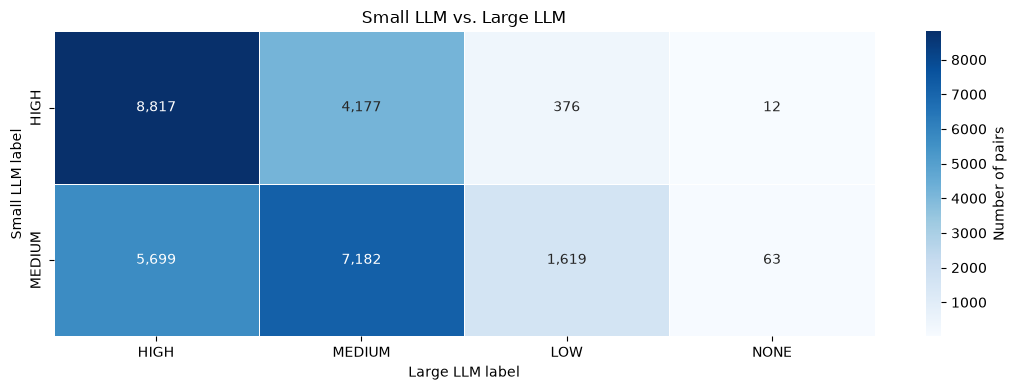

In [19]:
# Visual confusion matrix: one sequential color scale represents the number of pairs.
import matplotlib.pyplot as plt
import seaborn as sns

label_translation = {
    'ALTA': 'HIGH',
    'MEDIA': 'MEDIUM',
    'BAIXA': 'LOW',
    'NENHUMA': 'NONE',
    'NAO_CHEGOU_AO_MODELO_GRANDE': 'DID NOT REACH QWEN3',
}
matriz_heatmap = (matriz_transicao.drop(columns='TOTAL_MISTRAL')
                   .rename(index=label_translation, columns=label_translation))
plt.figure(figsize=(11, 4))
sns.heatmap(
    matriz_heatmap,
    annot=True,
    fmt=',.0f',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Number of pairs'},
)
plt.title('Small LLM vs. Large LLM')
plt.xlabel('Large LLM label')
plt.ylabel('Small LLM label')
plt.tight_layout()
plt.savefig('matriz_confusao_mistral_vs_qwen3.png', dpi=300, bbox_inches='tight')
plt.show()